# Explore HOTA outputs for OTIF

just want to make some visualizations

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import cv2

In [2]:
### EDIT BEFORE PROCEEDING ###
label = "amsterdam-y11"

In [3]:
# get some video metadata

video_dir = f"/work/alenachao/tunnel/work/data/otif-dataset/dataset/{label}/test/video"

total_frames = 0
num_videos = 0
for filename in os.listdir(video_dir):
    if filename.endswith(".mp4"):
        path = os.path.join(video_dir, filename)
        cap = cv2.VideoCapture(path)
        frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        total_frames += frames
        cap.release()
        num_videos += 1

print(total_frames, num_videos)

54011 60


In [4]:
"""
get otif results

caldot1-test-ours-simple.txt example:
{"Name":"yolov3","Dims":[704,480],"Sizes":[[704,480],[256,256]],"Threshold":0.25}	416_256_-1	{"NumFrames":0,"Thresholds":[0,0,1,1,1,1,1]}	16069	0.9513858926567258	0.9501476541317871	0.015037475384549803
{"Name":"yolov3","Dims":[704,480],"Sizes":[[704,480],[256,256]],"Threshold":0.25}	416_256_-1	{"NumFrames":0,"Thresholds":[0,0,0,1,1,1,1]}	8138	0.9544560786435786	0.956625559396457	0.012998307531070915

(detector_cfg    segmentation_cfg    tracker_cfg     runtime (per video... need to convert)   validation acc      test acc        stderr)
"""

otif_dir = f"/work/alenachao/tunnel/work/otif/pipeline2/outputs/{label}-test-ours-simple.txt"
otif_df = pd.read_csv(otif_dir, sep="\t", header=None)
otif_df[3] = otif_df[3] / 1000. * num_videos 
otif_df[4] = otif_df[4] / 1000.
otif_df[5] = otif_df[5] / 1000.
otif_df[6] = otif_df[6] / 1000.
otif_df[7] = otif_df[7] / 1000.
otif_df = otif_df.rename(columns={0: 'detector_cfg', 1: 'segmentation_cfg', 2: 'tracker_cfg', \
                                  3: 'runtime_total', 4: 'seg time', 5: 'detect time', \
                                  6: 'track time', 7: 'decode time', 8: 'val_acc', 9: 'test_acc', 10: 'stderr'})

# Columns (by index):
# 0 = detector cfg, 1 = segmentation cfg, 2 = tracker cfg, 3 = runtime,
# 4 = val acc, 5 = test acc, 6 = stderr
print(len(otif_df))
otif_df

10


,detector_cfg,segmentation_cfg,tracker_cfg,runtime_total,seg time,detect time,track time,decode time,val_acc,test_acc,stderr
0,"{""Name"":""yolov11"",""Dims"":[704,480],""Sizes"":[[7...",320_192_1e-05,"{""NumFrames"":0,""Thresholds"":[0,1,1,1,1,1,1]}",3576.54,1060.342,7273.895,533.538,0.034,0.783941,0.871319,0.027369
1,"{""Name"":""yolov11"",""Dims"":[704,480],""Sizes"":[[7...",320_192_1e-05,"{""NumFrames"":0,""Thresholds"":[0,0,1,1,1,1,1]}",1780.20,1471.007,10910.183,775.159,0.050,0.783941,0.872589,0.026450
2,"{""Name"":""yolov11"",""Dims"":[704,480],""Sizes"":[[7...",320_192_1e-05,"{""NumFrames"":0,""Thresholds"":[0,0,0,1,1,1,1]}",900.72,1553.972,12758.689,899.988,0.058,0.779497,0.853790,0.026453
3,"{""Name"":""yolov3"",""Dims"":[960,544],""Sizes"":[[96...",320_192_1e-05,"{""NumFrames"":0,""Thresholds"":[0,0,0,1,1,1,1]}",789.42,1663.622,14319.778,1060.221,0.066,0.772275,0.842576,0.030378
4,"{""Name"":""yolov3"",""Dims"":[736,416],""Sizes"":[[73...",320_192_1e-05,"{""NumFrames"":0,""Thresholds"":[0,0,0,1,1,1,1]}",747.84,1746.717,15845.346,1180.323,0.074,0.785052,0.843446,0.030429
5,"{""Name"":""yolov3"",""Dims"":[640,352],""Sizes"":[[64...",320_192_1e-05,"{""NumFrames"":0,""Thresholds"":[0,0,0,1,1,1,1]}",712.26,1819.275,17296.202,1284.318,0.082,0.786409,0.853872,0.030101
6,"{""Name"":""yolov3"",""Dims"":[416,256],""Sizes"":[[41...",320_192_1e-05,"{""NumFrames"":0,""Thresholds"":[0,0,0,1,1,1,1]}",790.56,1888.173,18924.773,1364.960,0.090,0.808015,0.835731,0.030679
7,"{""Name"":""yolov3"",""Dims"":[320,192],""Sizes"":[[32...",320_192_1e-05,"{""NumFrames"":0,""Thresholds"":[0,0,0,1,1,1,1]}",741.42,1943.801,20449.200,1431.121,0.098,0.805197,0.834218,0.030564
8,"{""Name"":""yolov3"",""Dims"":[320,192],""Sizes"":[[32...",320_192_1e-05,"{""NumFrames"":0,""Thresholds"":[0,0,0,0,1,1,1]}",365.40,1969.028,21230.072,1466.223,0.102,0.797155,0.835345,0.031426
9,"{""Name"":""yolov3"",""Dims"":[320,192],""Sizes"":[[32...",320_192_1e-05,"{""NumFrames"":0,""Thresholds"":[0,0,0,0,0,1,1]}",181.80,1984.017,21633.236,1485.840,0.104,0.814179,0.821964,0.031465


In [5]:
## no longer need HOTA scores
save_dir = f"/work/alenachao/tunnel/hota_outputs/{label}"
os.makedirs(save_dir, exist_ok=True) 

out_path = f"{save_dir}/otif_{label}.csv"
otif_df.to_csv(out_path)

In [23]:
"""
get trackeval results + combine with otif results

results are of the form
|-- 0.jsonl # 0th set of parameters
    |-- car_summary.txt # contains HOTA score
    ...
|-- 1.jsonl
    |-- car_summary.txt
    ...
...
car_summary.txt example:
HOTA DetA AssA DetRe DetPr AssRe AssPr LocA OWTA HOTA(0) LocA(0) HOTALocA(0) Dets GT_Dets IDs GT_IDs
48.482 50.121 46.898 50.237 99.537 47.759 97.338 99.773 48.539 48.719 99.525 48.487 375 744 10 10
"""

hota_dir = f"/data/alenachao/TrackEval/scripts/pipeline-stages/track-accuracy-otif-{label}/otif"
hota_rows = []

for param_dir in sorted(os.listdir(hota_dir), key=lambda x: int(x.split('.')[0]) if x.split('.')[0].isdigit() else -1):
    car_summary = os.path.join(hota_dir, param_dir, "car_summary.txt")
    if not os.path.exists(car_summary):
        hota_rows.append(None)
        continue

    with open(car_summary) as f:
        lines = f.read().strip().splitlines()
        if len(lines) >= 2:
            header = lines[0].split()
            values = list(map(float, lines[1].split()))
            hota_rows.append(dict(zip(header, values)))
        else:
            hota_rows.append(None)

# Convert HOTA results into a DataFrame
hota_df = pd.DataFrame(hota_rows).head(10)
print(f"Loaded {len(hota_df)} HOTA entries.")

# Merge the two DataFrames (row by row)
combined_df = pd.concat([otif_df, hota_df], axis=1)

# dropping params with no hota score
hota_columns = hota_df.columns.tolist()  # all HOTA metric columns
# combined_df = combined_df.dropna(subset=hota_columns, how='all').reset_index(drop=True)

# Display and verify
combined_df.head(10)

Loaded 6 HOTA entries.


,detector_cfg,segmentation_cfg,tracker_cfg,runtime_total,seg time,detect time,track time,decode time,val_acc,test_acc,...,AssPr,LocA,OWTA,HOTA(0),LocA(0),HOTALocA(0),Dets,GT_Dets,IDs,GT_IDs
0,"{""Name"":""retinanet"",""Dims"":[1080,720],""Sizes"":...",640_352_-1,"{""NumFrames"":0,""Thresholds"":[0,0,1,1,1,1,1]}",203.700,91.154,400.761,59.980,0.001,0.220675,0.261185,...,99.499,99.979,49.5780,49.5780,99.933,49.5450,59537.0,118591.0,534.0,503.0
1,"{""Name"":""retinanet"",""Dims"":[1080,720],""Sizes"":...",640_352_-1,"{""NumFrames"":0,""Thresholds"":[0,0,0,1,1,1,1]}",112.120,130.268,608.546,90.678,0.002,0.222359,0.255258,...,99.232,99.916,24.7430,24.7870,99.773,24.7310,29928.0,118591.0,525.0,503.0
2,"{""Name"":""retinanet"",""Dims"":[1080,720],""Sizes"":...",640_352_-1,"{""NumFrames"":0,""Thresholds"":[0,0,0,0,1,1,1]}",52.905,149.247,718.064,104.976,0.002,0.197436,0.241209,...,98.248,99.759,12.4700,12.5470,99.338,12.4640,15133.0,118591.0,474.0,503.0
3,"{""Name"":""retinanet"",""Dims"":[1080,720],""Sizes"":...",640_352_-1,"{""NumFrames"":0,""Thresholds"":[0,0,0,0,0,1,1]}",24.155,161.874,777.800,111.151,0.003,0.126477,0.218517,...,96.160,99.454,6.3192,6.4439,97.950,6.3118,7828.0,118591.0,480.0,503.0
4,"{""Name"":""retinanet"",""Dims"":[1080,720],""Sizes"":...",640_352_-1,"{""NumFrames"":0,""Thresholds"":[0,0,0,0,0,0,1]}",11.635,170.990,813.504,114.752,0.003,0.131101,0.147901,...,91.092,99.181,3.0743,3.1819,96.291,3.0638,4205.0,118591.0,577.0,503.0
5,"{""Name"":""retinanet"",""Dims"":[1080,720],""Sizes"":...",640_352_-1,"{""NumFrames"":0,""Thresholds"":[0,0,0,0,0,0,0]}",4.820,177.540,836.052,116.724,0.003,0.126923,0.114839,...,77.606,99.000,1.4370,1.5006,95.654,1.4354,2292.0,118591.0,698.0,503.0
6,"{""Name"":""retinanet"",""Dims"":[1080,720],""Sizes"":...",224_128_1.31072,"{""NumFrames"":0,""Thresholds"":[0,0,0,0,0,0,0]}",3.270,185.226,836.052,117.734,0.003,0.000000,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,"{""Name"":""retinanet"",""Dims"":[1080,720],""Sizes"":...",160_96_1.31072,"{""NumFrames"":0,""Thresholds"":[0,0,0,0,0,0,0]}",3.495,193.071,836.052,118.519,0.003,0.000000,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [24]:
# add throughput column
combined_df["fps"] = total_frames / combined_df['runtime']
combined_df.head(10)

KeyError: 'runtime'

In [46]:
combined_df.head(10)

,detector_cfg,segmentation_cfg,tracker_cfg,runtime,val_acc,test_acc,stderr,HOTA,DetA,AssA,...,LocA,OWTA,HOTA(0),LocA(0),HOTALocA(0),Dets,GT_Dets,IDs,GT_IDs,fps
0,"{""Name"":""yolov3"",""Dims"":[704,480],""Sizes"":[[70...",416_256_-1,"{""NumFrames"":0,""Thresholds"":[0,0,1,1,1,1,1]}",941.28,0.745227,0.868529,0.039037,46.8850,49.9110,44.0420,...,99.935,46.937,46.988,99.810,46.8990,132319.0,263577.0,2626.0,1669.0,75.535441
1,"{""Name"":""yolov3"",""Dims"":[704,480],""Sizes"":[[70...",416_256_-1,"{""NumFrames"":0,""Thresholds"":[0,0,0,1,1,1,1]}",489.42,0.746307,0.873430,0.038475,23.7990,25.0430,22.6170,...,99.890,23.821,23.907,99.601,23.8120,66446.0,263577.0,2026.0,1669.0,145.273998
2,"{""Name"":""yolov3"",""Dims"":[704,480],""Sizes"":[[70...",224_128_0.01024,"{""NumFrames"":0,""Thresholds"":[0,0,0,1,1,1,1]}",354.66,0.738716,0.864234,0.039234,46.8950,49.9220,44.0510,...,99.935,46.943,46.991,99.819,46.9060,132278.0,263577.0,2626.0,1669.0,200.473693
3,"{""Name"":""yolov3"",""Dims"":[704,480],""Sizes"":[[70...",416_256_0.00512,"{""NumFrames"":0,""Thresholds"":[0,0,0,1,1,1,1]}",287.28,0.728822,0.864139,0.038375,23.8040,25.0480,22.6220,...,99.878,23.827,23.919,99.581,23.8190,66491.0,263577.0,2026.0,1669.0,247.493734
4,"{""Name"":""yolov3"",""Dims"":[608,416],""Sizes"":[[60...",416_256_0.00512,"{""NumFrames"":0,""Thresholds"":[0,0,0,1,1,1,1]}",227.10,0.717353,0.856530,0.038953,23.2080,24.4830,22.0000,...,98.813,23.274,23.567,98.289,23.1640,66271.0,263577.0,2064.0,1669.0,313.077939
5,"{""Name"":""yolov3"",""Dims"":[512,352],""Sizes"":[[51...",416_256_0.00512,"{""NumFrames"":0,""Thresholds"":[0,0,0,1,1,1,1]}",188.04,0.724740,0.843769,0.039489,22.9240,23.9970,21.9030,...,97.776,23.025,23.536,97.005,22.8310,66100.0,263577.0,2068.0,1669.0,378.111040
6,"{""Name"":""yolov3"",""Dims"":[512,352],""Sizes"":[[51...",416_256_0.04096,"{""NumFrames"":0,""Thresholds"":[0,0,0,1,1,1,1]}",148.62,0.713604,0.852926,0.039112,17.7420,17.4840,18.4040,...,80.977,18.086,22.176,75.777,16.8040,64736.0,263577.0,2110.0,1669.0,478.401292
7,"{""Name"":""yolov3"",""Dims"":[512,352],""Sizes"":[[51...",416_256_0.04096,"{""NumFrames"":0,""Thresholds"":[0,0,0,0,1,1,1]}",70.44,0.709485,0.857142,0.038618,16.8710,16.7890,17.1780,...,80.457,17.159,21.325,75.053,16.0050,61823.0,263577.0,2109.0,1669.0,1009.369676
8,"{""Name"":""yolov3"",""Dims"":[512,352],""Sizes"":[[51...",416_256_0.04096,"{""NumFrames"":0,""Thresholds"":[0,0,0,0,0,1,1]}",34.86,0.685103,0.852295,0.036437,16.7350,16.6700,17.0290,...,80.461,17.019,21.120,75.077,15.8560,61339.0,263577.0,2138.0,1669.0,2039.586919
9,"{""Name"":""yolov3"",""Dims"":[416,288],""Sizes"":[[41...",416_256_0.04096,"{""NumFrames"":0,""Thresholds"":[0,0,0,0,0,1,1]}",27.24,0.602466,0.784980,0.039306,8.5843,8.4931,8.7945,...,80.397,8.664,10.806,74.800,8.0829,31072.0,263577.0,1790.0,1669.0,2610.132159


In [47]:
# visualization time
save_dir = f"/data/alenachao/outputs/hota_outputs/{label}"
os.makedirs(save_dir, exist_ok=True) 

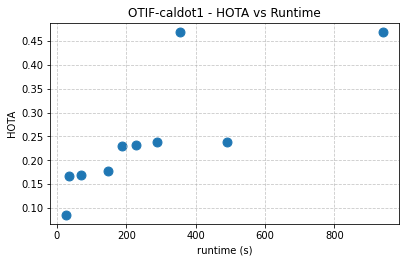

In [48]:
# plot acc vs runtime
fig, ax = plt.subplots(figsize=(6, 4))
sc = ax.scatter(combined_df['runtime'], combined_df["HOTA"] / 100, cmap="viridis", s=80)
ax.set_xlabel("runtime (s)")
ax.set_ylabel("HOTA")
ax.set_title(f"OTIF-{label} - HOTA vs Runtime")
ax.grid(True, linestyle="--", alpha=0.7)

# Adjust layout so title and labels are not cropped
fig.tight_layout(pad=2.0)  # pad=2.0 gives extra space

# Save
save_path = os.path.join(save_dir, f"otif_{label}_hota_vs_runtime.png")
fig.savefig(save_path, dpi=300, facecolor='white')

plt.show()


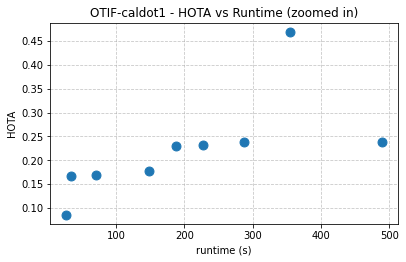

In [49]:
# zoom in
otif_runtime = combined_df[combined_df['runtime'] < 800]

# Create figure with white background
fig, ax = plt.subplots(figsize=(6, 4), facecolor='white')
sc = ax.scatter(otif_runtime['runtime'], otif_runtime["HOTA"] / 100, cmap="viridis", s=80)

ax.set_xlabel("runtime (s)")
ax.set_ylabel("HOTA")
ax.set_title(f"OTIF-{label} - HOTA vs Runtime (zoomed in)")
ax.grid(True, linestyle="--", alpha=0.7)

# Adjust layout to fit title/labels
fig.tight_layout(pad=2.0)

# Save
save_path = os.path.join(save_dir, f"otif_{label}_hota_vs_runtime_zoomed.png")
fig.savefig(save_path, dpi=300, facecolor='white')

plt.show()

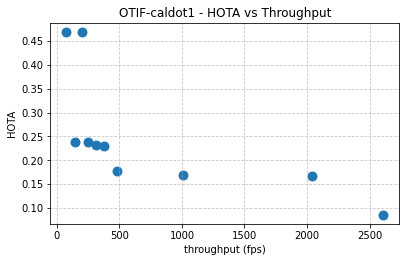

In [50]:
# ACC vs Throughput
fig, ax = plt.subplots(figsize=(6, 4), facecolor='white')
sc = ax.scatter(combined_df['fps'], combined_df["HOTA"] / 100, cmap="viridis", s=80)

ax.set_xlabel("throughput (fps)")
ax.set_ylabel("HOTA")
ax.set_title(f"OTIF-{label} - HOTA vs Throughput")
ax.grid(True, linestyle="--", alpha=0.7)

# Adjust layout so title and labels are not cropped
fig.tight_layout(pad=2.0)

# Save
save_path = os.path.join(save_dir, f"otif_{label}_hota_vs_throughput.png")
fig.savefig(save_path, dpi=300, facecolor='white')

plt.show()

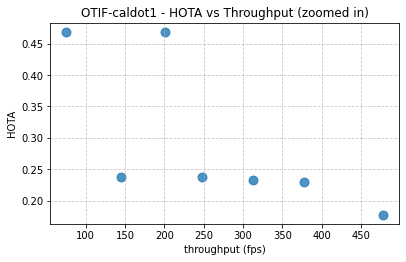

In [51]:
# zoom in
otif_throughput = combined_df[combined_df['fps'] < 500]

# Create figure with white background
fig, ax = plt.subplots(figsize=(6, 4), facecolor='white')
sc = ax.scatter(
    otif_throughput['fps'], 
    otif_throughput["HOTA"] / 100, 
    cmap="viridis", 
    s=80, 
    alpha=0.8
)

ax.set_xlabel("throughput (fps)")
ax.set_ylabel("HOTA")
ax.set_title(f"OTIF-{label} - HOTA vs Throughput (zoomed in)")
ax.grid(True, linestyle="--", alpha=0.7)

# Adjust layout to fit title/labels
fig.tight_layout(pad=2.0)

# Save
save_path = os.path.join(save_dir, f"otif_{label}_hota_vs_throughput_zoomed.png")
fig.savefig(save_path, dpi=300, facecolor='white')

plt.show()

In [52]:
# export
out_path = f"{save_dir}/otif_{label}.csv"
combined_df.to_csv(out_path)